<a href="https://colab.research.google.com/github/Min414/Bank-Customer-Churn-Analysis/blob/main/Bank_churn_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd

df = pd.read_csv("Churn_Modelling.csv")
df.head()


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [12]:
df = df.drop(['RowNumber', 'CustomerId', 'Surname'], axis=1)
print(df['Exited'].mean())
print(df.groupby('Geography')['Exited'].mean())
print(df.groupby('Gender')['Exited'].mean())
print(df.groupby('IsActiveMember')['Exited'].mean())

0.2037
Geography
France     0.161548
Germany    0.324432
Spain      0.166734
Name: Exited, dtype: float64
Gender
Female    0.250715
Male      0.164559
Name: Exited, dtype: float64
IsActiveMember
0    0.268509
1    0.142691
Name: Exited, dtype: float64


In [13]:
# Checking for numeric drivers
print(df.groupby('NumOfProducts')['Exited'].mean())
print(df.groupby('Exited')[['Age', 'Balance', 'CreditScore']].mean())

NumOfProducts
1    0.277144
2    0.075817
3    0.827068
4    1.000000
Name: Exited, dtype: float64
              Age       Balance  CreditScore
Exited                                      
0       37.408389  72745.296779   651.853196
1       44.837997  91108.539337   645.351497


In [14]:
# Checking for customers with 0 balance
print((df['Balance'] == 0).mean())
print(df.groupby(df['Balance'] == 0)['Exited'].mean())
print(df[df['Balance'] > 0].groupby('Exited')['Balance'].mean())

0.3617
Balance
False    0.240796
True     0.138236
Name: Exited, dtype: float64
Exited
0    119535.864270
1    120746.971132
Name: Balance, dtype: float64


In [19]:
# Adding a flag for no balance customers
df['HasBalance'] = (df['Balance'] > 0).astype(int)
df[['Balance', 'HasBalance']].head()

,Balance,HasBalance
0,0.00,0
1,83807.86,1
2,159660.80,1
3,0.00,0
4,125510.82,1


In [20]:
# baseline model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

X = pd.get_dummies(df.drop('Exited', axis=1), drop_first=True)
y = df['Exited']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression(max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.90      0.70      0.79      1593
           1       0.37      0.70      0.49       407

    accuracy                           0.70      2000
   macro avg       0.64      0.70      0.64      2000
weighted avg       0.79      0.70      0.73      2000



/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [21]:
# Using random forest
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)
print(classification_report(y_test, rf.predict(X_test)))

              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.78      0.44      0.56       407

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.85      0.86      0.85      2000



In [22]:
# Tuning cutoff to catch more exiters
probs = rf.predict_proba(X_test)[:, 1]
for t in [0.5, 0.4, 0.3]:
    print(t)
    print(classification_report(y_test, (probs >= t).astype(int)))

0.5
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1593
           1       0.77      0.45      0.57       407

    accuracy                           0.86      2000
   macro avg       0.82      0.71      0.74      2000
weighted avg       0.85      0.86      0.85      2000

0.4
              precision    recall  f1-score   support

           0       0.89      0.93      0.91      1593
           1       0.68      0.55      0.61       407

    accuracy                           0.86      2000
   macro avg       0.79      0.74      0.76      2000
weighted avg       0.85      0.86      0.85      2000

0.3
              precision    recall  f1-score   support

           0       0.91      0.87      0.89      1593
           1       0.57      0.65      0.61       407

    accuracy                           0.83      2000
   macro avg       0.74      0.76      0.75      2000
weighted avg       0.84      0.83      0.83      2000



In [23]:
# Feature importance
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)

Age                  0.252137
EstimatedSalary      0.138251
NumOfProducts        0.133351
CreditScore          0.132674
Balance              0.128301
Tenure               0.081700
IsActiveMember       0.035359
Geography_Germany    0.030285
Gender_Male          0.020714
HasCrCard            0.017899
Geography_Spain      0.015173
HasBalance           0.014154
dtype: float64


In [26]:
# Permutation Importance
from sklearn.inspection import permutation_importance

r = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=42, scoring='f1')
pd.Series(r.importances_mean, index=X.columns).sort_values(ascending=False)

,0
Age,0.201827
NumOfProducts,0.192651
Geography_Germany,0.074275
IsActiveMember,0.061193
Balance,0.040218
Tenure,0.008153
EstimatedSalary,0.004380
CreditScore,0.003395
Geography_Spain,0.003052
Gender_Male,0.001200


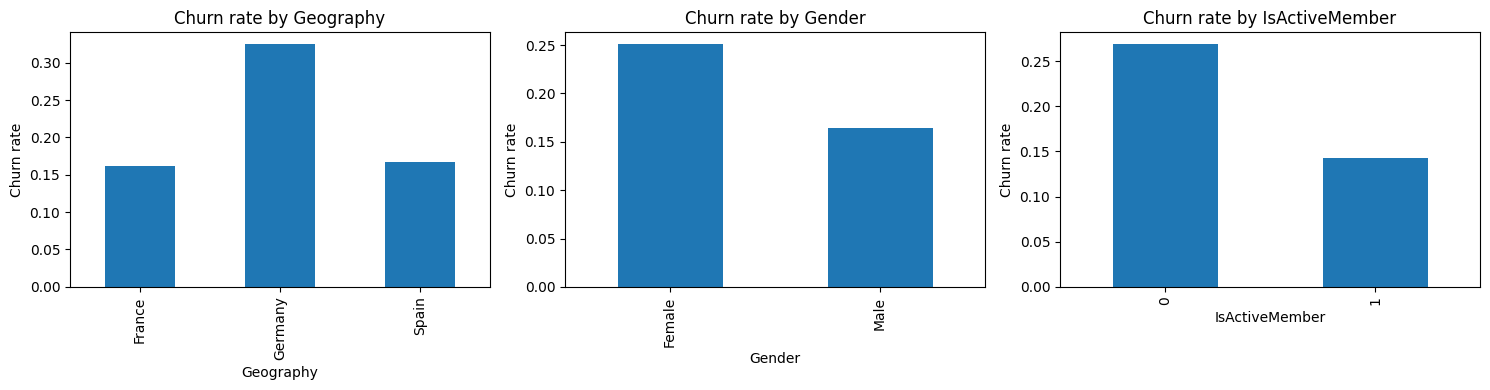

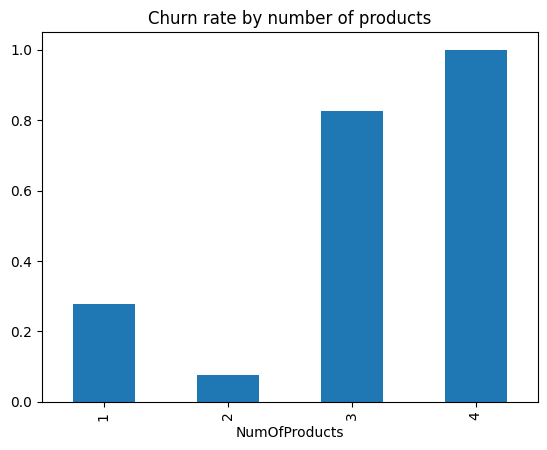

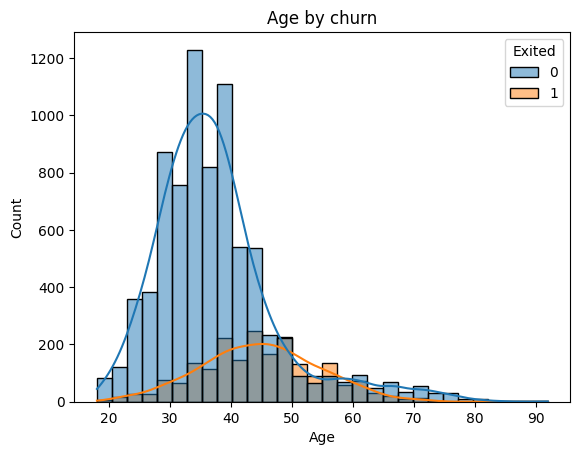

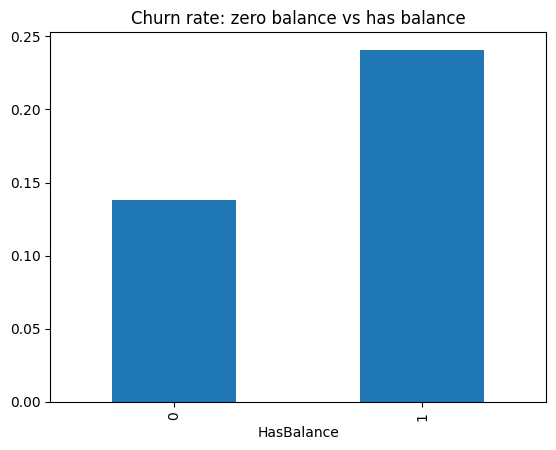

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

# Churn rate by group
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['Geography', 'Gender', 'IsActiveMember']):
    df.groupby(col)['Exited'].mean().plot(kind='bar', ax=ax)
    ax.set_title(f'Churn rate by {col}')
    ax.set_ylabel('Churn rate')
plt.tight_layout()
plt.show()

# Churn rate by number of products
df.groupby('NumOfProducts')['Exited'].mean().plot(kind='bar')
plt.title('Churn rate by number of products')
plt.show()

# Age distribution: churned vs stayed
sns.histplot(data=df, x='Age', hue='Exited', bins=30, kde=True)
plt.title('Age by churn')
plt.show()

# Zero balance vs has balance
df.groupby('HasBalance')['Exited'].mean().plot(kind='bar')
plt.title('Churn rate: zero balance vs has balance')
plt.show()